#### Optimization Algorithms AI techniques for design, planning, and control problems

Travelling Salesman Problem

In [ ]:
%%capture
!pip install haversine simanneal > dev/null

In [ ]:
import pandas as pd
import numpy as np

import random

from matplotlib import pyplot as plt

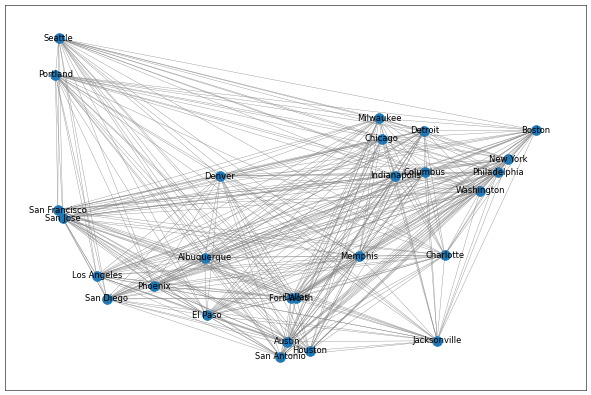

In [ ]:
import networkx as nx
from collections import defaultdict
from haversine import haversine

# use distances or latitude/longtitude for the major cities.
cities = {
    'New York': (40.7128, -74.0060),
    'Los Angeles': (34.0522, -118.2437),
    'Chicago': (41.8781, -87.6298),
    'Houston': (29.7604, -95.3698),
    'Phoenix': (33.4484, -112.0740),
    'Philadelphia': (39.9526, -75.1652),
    'San Antonio': (29.4241, -98.4936),
    'San Diego': (32.7157, -117.1611),
    'Dallas': (32.7767, -96.7970),
    'San Jose': (37.3382, -121.8863),
    'Austin': (30.2672, -97.7431),
    'Jacksonville': (30.3322, -81.6557),
    'Fort Worth': (32.7554, -97.3307),
    'Columbus': (39.9612, -82.9988),
    'San Francisco': (37.7749, -122.4194),
    'Charlotte': (35.2271, -80.8431),
    'Indianapolis': (39.7684, -86.1581),
    'Seattle': (47.6062, -122.3321),
    'Denver': (39.7392, -104.9903),
    'Washington': (38.9072, -77.0369),
    'Boston': (42.3601, -71.0589),
    'El Paso': (31.7772, -106.4424),
    'Detroit': (42.3314, -83.0458),
    'Portland': (45.5231, -122.6765),
    'Memphis': (35.1495, -90.0490),
    'Milwaukee': (43.0389, -87.9064),
    'Albuquerque': (35.0853, -106.6501),
}

# distance matrix based on latitude-longtitude coordinates
distance_matrix = defaultdict(dict)
for (city_a, coord_a) in cities.items():
    for city_b, coord_b in cities.items():
       distance_matrix[city_a][city_b] = 0.0 if  coord_a==coord_b else haversine(coord_a, coord_b)

# convert the distance matrix into a dataframe
distances = pd.DataFrame(distance_matrix)
cities_list = list(distances.columns)
distances = distances.values

# visualize the vities and route
G = nx.Graph()
for city_a, coord_a in cities.items():
    for city_b, coord_b in cities.items():
        if city_a != city_b:
            G.add_edge(city_a, city_b, weight=distance_matrix[city_a][city_b])

fig, ax = plt.subplots(figsize=(15, 10), dpi=50)
# reverse lat and long for correct visualization
reversed_dict = {key: value[::-1] for key, value in cities.items()}
# a shallow copy of graph and attributes
G_copy = G.copy()
#visualize network
ax = nx.draw_networkx(
    G_copy,
    pos=reversed_dict,
    with_labels=True,
    edge_color='gray',
    node_size=200,
    #node_color='skyblue',
    #font_size=10,
    width=0.5,
)

TSP Solver using Google's OR-Tools developed for solving linear programming (LP), mixed integer programming (MILPS), constraint programming, and vehicle routing.

In [ ]:
!pip install ortools > /dev/null

In [ ]:
import ortools
from ortools.constraint_solver import routing_enums_pb2
from ortools.constraint_solver import pywrapcp

#  convert float array into integer array for OR-tools
distnaces_int = np.array(distances, dtype=int)
data = {}
data['distance_matrix'] = distnaces_int
data['num_vehicles'] = 1
data['depot'] = 0

# define solver
manager = pywrapcp.RoutingIndexManager(
    len(data['distance_matrix']),
    data['num_vehicles'],
    data['depot']
)
routing = pywrapcp.RoutingModel(manager)

def distance_callback(from_index, to_index):
    """Returns the distance between the two nodes."""
    # Convert from routing variable Index to distance matrix NodeIndex.
    from_node = manager.IndexToNode(from_index)
    to_node = manager.IndexToNode(to_index)
    return data['distance_matrix'][from_node][to_node]

transit_callback_index = routing.RegisterTransitCallback(distance_callback)
routing.SetArcCostEvaluatorOfAllVehicles(transit_callback_index)

# search parameters
search_parameters = pywrapcp.DefaultRoutingSearchParameters()
#search_parameters.first_solution_strategy = ( routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC )
search_parameters.local_search_metaheuristic = (
    routing_enums_pb2.LocalSearchMetaheuristic.TABU_SEARCH )
search_parameters.time_limit.seconds = 30
search_parameters.log_search = True

# print solution
def print_solution(manager, routing, solution):
    """Prints solution on console."""
    print(f'Objective: {solution.ObjectiveValue()}')
    index = routing.Start(0)
    plan_output = 'Route for vehicle 0:\n'
    route_distance = 0
    while not routing.IsEnd(index):
        plan_output += f' {cities_list[manager.IndexToNode(index)]} -> '
        previous_index = index
        index = solution.Value(routing.NextVar(index))
        route_distance += routing.GetArcCostForVehicle(previous_index, index, 0)
    plan_output += f'{cities_list[manager.IndexToNode(index)]}\n'
    print(plan_output)
    plan_output += f'Distance of the route: {route_distance}m\n'

solution = routing.SolveWithParameters(search_parameters)
if solution:
    print_solution(manager, routing, solution)

Objective: 13153
Route for vehicle 0:
 New York ->  Philadelphia ->  Washington ->  Charlotte ->  Jacksonville ->  Memphis ->  Dallas ->  Fort Worth ->  Houston ->  Austin ->  San Antonio ->  El Paso ->  Albuquerque ->  Phoenix ->  San Diego ->  Los Angeles ->  San Jose ->  San Francisco ->  Portland ->  Seattle ->  Denver ->  Milwaukee ->  Chicago ->  Indianapolis ->  Columbus ->  Detroit ->  Boston -> New York



TSP Solver using simulated annealing

In [ ]:
import random
from simanneal import Annealer

class TravellingSalesmanProblem(Annealer):
    """Travelling Salesman Problem solver using Simulated Annealing."""
    def __init__(self, state, distance_matrix):
        self.distance_matrix = distance_matrix
        super(TravellingSalesmanProblem, self).__init__(state)

    def move(self):
        """Swaps two cities in the route."""
        # no efficiency gain, show returning the delta energy
        inital_energy_state = self.energy()

        a = random.randint(0, len(self.state) - 1)
        b = random.randint(0, len(self.state) - 1)
        self.state[a], self.state[b] = self.state[b], self.state[a]
        return self.energy() - inital_energy_state

    def energy(self):
        """Calculates total route distance."""
        e = 0
        for i in range(len(self.state)):
            e += self.distance_matrix[self.state[i - 1]][self.state[i]]
        return e

# Create a random initial route
city_names = list(cities.keys())
initial_state = list(city_names)
random.shuffle(initial_state)

# Instantiate and run TSP with simulated annealing
tsp = TravellingSalesmanProblem(initial_state, distance_matrix)
tsp.set_schedule(tsp.auto(minutes=0.1)) #minutes=0.001
tsp.steps = 20000
tsp.copy_strategy = "slice"
state, e = tsp.anneal()

print(f"\nOptimal Route: {' -> '.join(state)}")
print(f"Optimal Distance: {e:.2f} km")

 Temperature        Energy    Accept   Improve     Elapsed   Remaining
 Temperature        Energy    Accept   Improve     Elapsed   Remaining



Optimal Route: Los Angeles -> San Jose -> San Francisco -> Portland -> Seattle -> Denver -> Milwaukee -> Detroit -> Boston -> New York -> Philadelphia -> Washington -> Jacksonville -> Charlotte -> Columbus -> Indianapolis -> Chicago -> Memphis -> Houston -> San Antonio -> Austin -> Dallas -> Fort Worth -> El Paso -> Albuquerque -> Phoenix -> San Diego
Optimal Distance: 14219.47 km


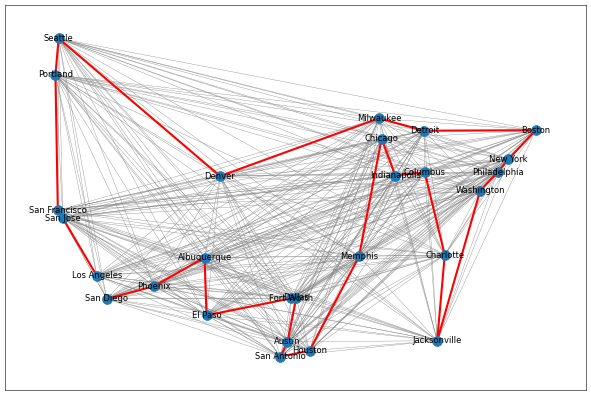

In [ ]:
fig, ax = plt.subplots(figsize=(15, 10), dpi=50)
# reverse lat and long for correct visualization
reversed_dict = {key: value[::-1] for key, value in cities.items()}
H = G.copy()
edge_list = list(nx.utils.pairwise(state))
# draw the closest edges on each node
nx.draw_networkx_edges(
    H,
    pos=reversed_dict,
    edge_color='gray',
    width=0.5
)
# draw the route
ax = nx.draw_networkx(
    H,
    pos=reversed_dict,
    with_labels=True,
    edgelist=edge_list,
    edge_color='red',
    node_size=200,
    width=3
)

TSP Solver using DEAP (Distributed Evolutionary Algorithms in Python).
DEAP is an evolutionary computation framework for rapid prototyping and testing of ideas.

In [ ]:
!pip install deap > /dev/null

In [ ]:
from deap import base, creator, tools, algorithms

In [ ]:
# create a fitness function that minimizes the total distance
creator.create('fitnessMin', base.Fitness, weights=(-1.0,))
creator.create('Individual', list, fitness=creator.fitnessMin)

# create the genetic oprator functions
toolbox = base.Toolbox()
toolbox.register('indices', random.sample, range(len(cities_list)), len(cities_list))
toolbox.register('permutation', random.sample, range(len(cities_list)), len(cities_list))
toolbox.register('individual', tools.initIterate, creator.Individual, toolbox.indices)
toolbox.register('population', tools.initRepeat, list, toolbox.individual)


def evalTSP(individual):
    total_distance = 0
    for i in range(len(individual)):
        city_1 = individual[i]
        city_2 = individual[(i + 1) % len(individual)]
        total_distance += distances[city_1][city_2]
        '''
        total_distance += distance_matrix[individual[i]][individual[i + 1]]
        '''
    total_distance += distances[individual[-1]][individual[0]]
    return (total_distance,)  # Must return a tuple

toolbox.register('evaluate', evalTSP)
toolbox.register('mate', tools.cxOrdered)
toolbox.register('mutate', tools.mutShuffleIndexes, indpb=0.05)
toolbox.register('select', tools.selTournament, tournsize=3)

# run the genetic algorithm
def main_alg():
    pop = toolbox.population(n=50)
    hof = tools.HallOfFame(1)
    stats = tools.Statistics(lambda ind: ind.fitness.values)
    stats.register('avg', np.mean)
    stats.register('std', np.std)
    stats.register('min', np.min)
    stats.register('max', np.max)
    pop, log = algorithms.eaSimple(
        pop, toolbox, cxpb=0.5, mutpb=0.2, ngen=100, stats=stats, halloffame=hof,  verbose=True
    )
    best_individual = hof[0]
    print('best solution')
    print('fitness: ', evalTSP(best_individual)[0])
    print('route: ', [city_names[i] for i in best_individual])

main_alg()

/usr/local/lib/python3.13/dist-packages/deap/creator.py:185: RuntimeWarning: A class named 'fitnessMin' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "
/usr/local/lib/python3.13/dist-packages/deap/creator.py:185: RuntimeWarning: A class named 'Individual' has already been created and it will be overwritten. Consider deleting previous creation of that class or rename it.
  warnings.warn("A class named '{0}' has already been created and it "


gen	nevals	avg    	std   	min    	max    
0  	50    	54238.1	5025.9	43690.4	63609.1
1  	37    	49748.3	4164.77	40508.5	58364.5
2  	21    	46446.7	3827.37	40461.7	56159.7
3  	32    	44935.8	4320.17	35100.4	53972.8
4  	32    	42949.3	3601.28	35851.1	52032.3
5  	29    	42199.4	4465.34	34813.2	58609.3
6  	29    	40283.4	3691.16	34024.2	50412.8
7  	24    	38690.7	3781.13	34024.2	52761.6
8  	25    	37698.5	3406.05	30494.4	47008.8
9  	23    	36716.3	3277.95	32164.4	46630.6
10 	28    	36619.9	4086.36	30603  	47278.7
11 	22    	35272.6	3053.72	30603  	43624  
12 	36    	35278.8	3661.38	30603  	47388.4
13 	25    	34231.7	2451.85	30603  	40196.1
14 	30    	33821.1	3385.74	30603  	49324.6
15 	28    	33639  	4079.6 	29893.6	45908.2
16 	29    	32367.9	2662.67	29893.6	45084.6
17 	36    	31960.9	2756.35	28558.8	43101.7
18 	32    	32650.2	4331.32	28558.8	48678.7
19 	21    	31744.7	3469.98	28558.8	43708.5
20 	26    	31182.8	2651.1 	28558.8	40386.2
21 	27    	31164.4	4211.08	28558.8	46876.3
22 	32    	30